# Assignment 4
Name: <font color=blue>______文杰______</font>,       ID: <font color=blue>______123090612______</font>

In [35]:
import numpy as np
import matplotlib.pylab as plt
import math

### Helpful functions
The following functions may be helpful for your coding, but you can also choose to code it by yourself or modify it.

#### plot the two figures

In [36]:
def Poisson1(lam):
    '''
    Parameters:
    ----------
    lam : float
        rate

    Returns
    -------
    A list or an array
        arrival times on interval [0,time].
    '''
    arrival_times = []
    current_time = 0
    while True:
        inter_arrival_time = np.random.exponential(1 / lam)  # Exponential with rate lam
        current_time += inter_arrival_time
        if current_time > time:
            break
        arrival_times.append(current_time)
    return arrival_times

In [37]:
def plot1(numbers, lam):
    '''
    For problem 5-2
    Parameters:
    ----------
    numbers: a list or an array with type int
        collections of the total number of arrivals for each round
    lam : float
        rate
    '''
    p = lambda k: np.exp(-lam) * lam**k / math.factorial(k)  # Use math.factorial instead of np.math.factorial
    x = list(range(0, np.max(numbers) + 1))
    plt.figure()
    plt.hist(numbers, range=(0, np.max(numbers) + 1), bins=np.max(numbers) + 1, 
             alpha=0.5, rwidth=0.5, label='empirical', color='orange', density=True)
    plt.bar(x, [p(k) for k in x], alpha=0.5, width=0.5, label='theoretic')
    plt.xlabel(f'the number of arrivals on [0, {time}]')
    plt.ylabel('probability')
    plt.legend(loc='upper left')
    plt.show()

Note that the intensity has the relation with the frequency:
$$\text{intensity}\times \text{bin width} = \text{frequency}$$

If you want to sample from some distributions, you can use `np.random`. For example
- exponential random variable with rate $\lambda$ can be sampled by `np.random.exponential(1/lambda)` (see [docs](https://numpy.org/doc/stable/reference/random/generated/numpy.random.exponential.html))
- poisson random variable with mean $\lambda$ can be sampled by  `np.random.poisson(lambda)` (see [docs](https://numpy.org/doc/stable/reference/random/generated/numpy.random.poisson.html))
- uniform random variable with range [low, high] can be sampled by  `np.random.uniform(low,high,size=n)` (see [docs](https://numpy.org/doc/stable/reference/random/generated/numpy.random.uniform.html))

## Question 5

In [38]:
time = 1 # we just focus on the interval [0,1] in this problem.
np.random.seed(42) # set random seed for reproduction.

### 5-1
Write two functions **Poisson1** and **Poisson2** to simulate the sequence of arrival times of events on $[0,1]$ for a Poisson process with rate $\lambda$, where $\lambda$ is the input to your functions. In **Poisson1**, the simulation is based on generating i.i.d. inter-arrival times. In **Poisson2**, you first generate the total number of arrivals and then the conditional distribution of arrival times.

In [39]:
def Poisson1(lam):
    '''
    Parameters:
    ----------
    lam : float
        rate

    Returns
    -------
    A list or an array
        arrival times on interval [0,time].
    '''
    arrival_times = []
    current_time = 0
    while True:
        inter_arrival_time = np.random.exponential(1 / lam)  # Exponential with rate lam
        current_time += inter_arrival_time
        if current_time > time:
            break
        arrival_times.append(current_time)
    return arrival_times

In [40]:
def Poisson2(lam):
    '''
    Parameters:
    ----------
    lam : float
        rate

    Returns
    -------
    A list or an array
        arrival times on interval [0,time].
    '''
    N = np.random.poisson(lam * time)  # Number of arrivals in [0,1]
    if N == 0:
        return []  # No arrivals
    arrival_times = np.random.uniform(0, time, N)  # N uniform times in [0,1]
    arrival_times.sort()  # Sort in ascending order
    return arrival_times

### 5-2
Set $\lambda =10$. Run **Poisson1** for 10000 rounds, record the total number of arrivals in each round. Plot the empirical distribution of the simulated number of arrivals, and validate your codes by comparing the empirical distribution with the theoretical distribution.

In [41]:
lam = 10
N = 10000

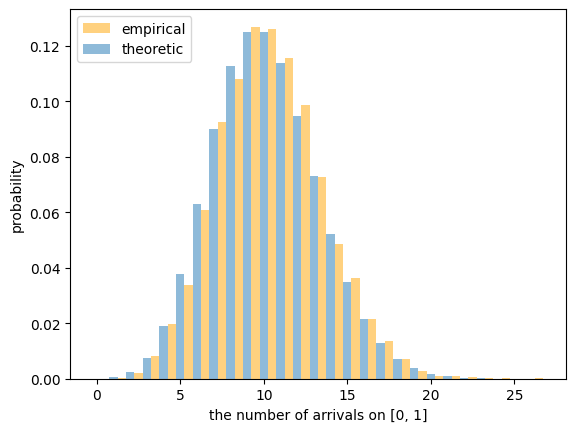

In [42]:
# Simulate total number of arrivals
numbers = [len(Poisson1(lam)) for _ in range(N)]

# Run the plot
plot1(numbers, lam * time)

### 5-3
Run **Poisson2** for 10000 rounds, record the first arrival time. (What if there is no arrival on $[0,1]$?) Plot the empirical distribution of the first arrival time, and validate your codes by comparing the empirical distribution with the theoretical distribution.

In [43]:
lam = 10
N = 10000

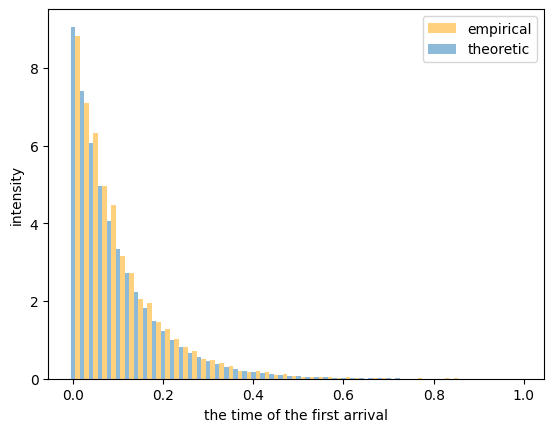

In [44]:
# Simulate first arrival times
first_arrivals = []
for _ in range(N):
    arrivals = Poisson2(lam)
    if len(arrivals) > 0:  # Only record if there’s at least one arrival
        first_arrivals.append(arrivals[0])

# Run the plot with 50 bins
plot2(first_arrivals, lam, bins=50)